In [5]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns

# ---- NeurIPS-style rcParams ----
mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Nimbus Roman", "DejaVu Serif"],
    "font.size": 9,
    "axes.titlesize": 11,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.linewidth": 0.6,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,   # embed as TrueType, not Type 3 -- required by many venues
    "ps.fonttype": 42,
})

DEFAULT_FAMILY_COLORS = {
    "astropt": "#4d4d4d",
    "convnext": "#e41a1c",
    "dino": "#4daf4a",
    "ijepa": "#984ea3",
    "vit": "#ff7f00",
}

def plot_failure_overlap_heatmap(
    input_csv,
    output_path,
    figsize=(10, 9),
    title="Failure Overlap Between Foundation Models (90% coverage)",
    cbar_label="Jaccard similarity (shared failures / combined failures)",
    family_colors=None,
):
    """
    Read a long-format failure CSV, compute pairwise Jaccard overlap
    between models' failure sets, and save a heatmap.

    input_csv : path to a CSV with columns ["Model", "row_id"]
    output_path : where to save the figure (.png, .pdf, .svg, ...)
    family_colors : optional dict overriding/extending DEFAULT_FAMILY_COLORS
    """
    df = pd.read_csv(input_csv)

    models = sorted(df["Model"].unique())
    uncovered_sets = {
        m: set(df.loc[df["Model"] == m, "row_id"]) for m in models
    }

    jaccard = pd.DataFrame(
        [[len(uncovered_sets[m1] & uncovered_sets[m2]) / len(uncovered_sets[m1] | uncovered_sets[m2])
          if uncovered_sets[m1] | uncovered_sets[m2] else 0.0
          for m2 in models] for m1 in models],
        index=models, columns=models,
    )

    mask = np.eye(len(models), dtype=bool)          # hide the trivial diagonal (always 1.00)
    vmax = jaccard.values[~mask].max()               # scale color to the actual max, not 1.0

    # resolve a color per family: defaults + auto-fill for anything unlisted
    families = sorted({m.rsplit("_", 1)[0] for m in models})
    palette = sns.color_palette("Set1", n_colors=len(families))
    colors = dict(family_colors) if family_colors else dict(DEFAULT_FAMILY_COLORS)
    for fam, auto_color in zip(families, palette):
        colors.setdefault(fam, auto_color)

    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        jaccard, mask=mask, cmap="rocket_r", vmin=0, vmax=vmax,
        annot=True, fmt=".2f", annot_kws={"size": 7},
        linewidths=0.4, linecolor="white",
        square=True, ax=ax,
        cbar_kws={"label": cbar_label},
    )
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    ax.set_title(title, pad=12)

    for label in ax.get_xticklabels() + ax.get_yticklabels():
        family = label.get_text().rsplit("_", 1)[0]
        label.set_color(colors.get(family, "black"))

    fig.savefig(output_path, bbox_inches="tight")
    return fig, ax

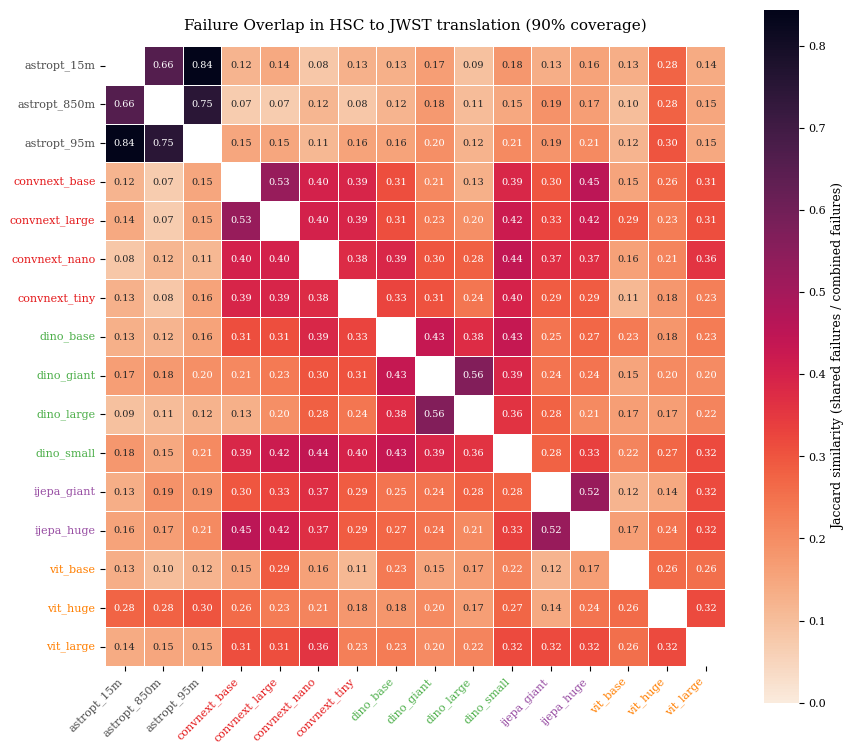

In [14]:
plot_failure_overlap_heatmap(
    input_csv="/mnt/datasets/universetbd_conformal/user_1/cross-survey-conformal-prediction/SVR/results/uncovered_objects_90%/hsc_jwst_uncovered.csv",
    output_path="/mnt/datasets/universetbd_conformal/user_1/cross-survey-conformal-prediction/SVR/results/uncovered_objects_90%_plots/uncovered_overlap_heatmap_hsc_jwst.png",
    title="Failure Overlap in HSC to JWST translation (90% coverage)"
)
plt.show()

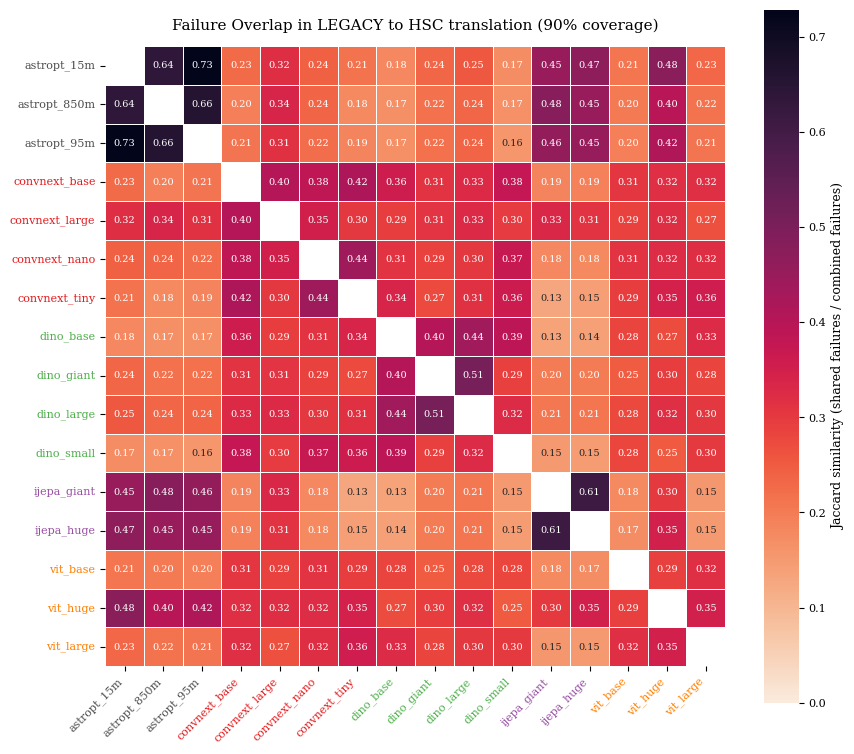

In [15]:
plot_failure_overlap_heatmap(
    input_csv="/mnt/datasets/universetbd_conformal/user_1/cross-survey-conformal-prediction/SVR/results/uncovered_objects_90%/legacy_hsc_uncovered.csv",
    output_path="/mnt/datasets/universetbd_conformal/user_1/cross-survey-conformal-prediction/SVR/results/uncovered_objects_90%_plots/uncovered_overlap_heatmap_legacy_hsc.png",
    title="Failure Overlap in LEGACY to HSC translation (90% coverage)"
)
plt.show()

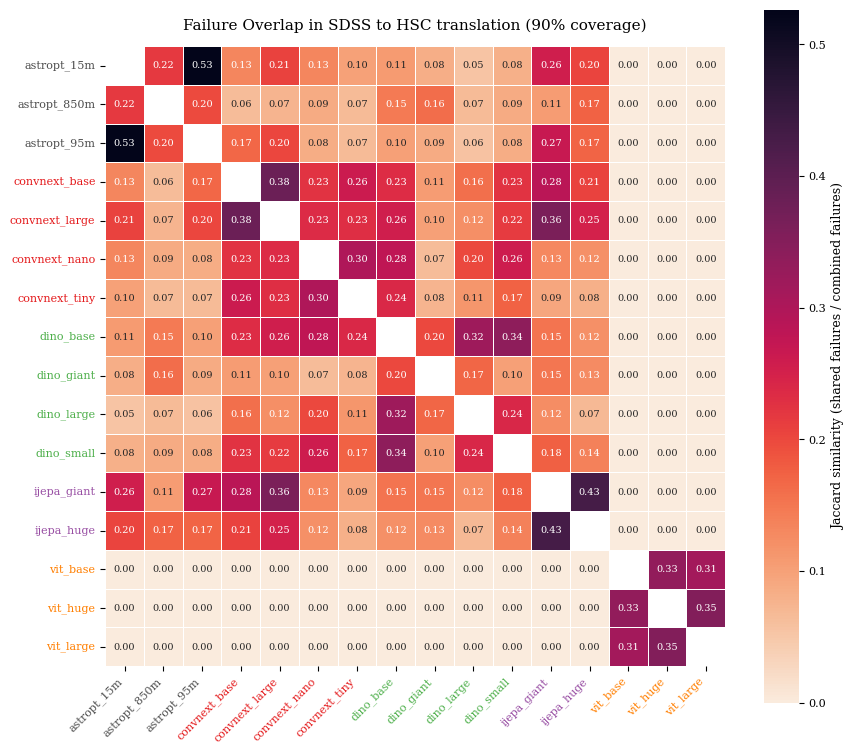

In [16]:
plot_failure_overlap_heatmap(
    input_csv="/mnt/datasets/universetbd_conformal/user_1/cross-survey-conformal-prediction/SVR/results/uncovered_objects_90%/sdss_hsc_uncovered.csv",
    output_path="/mnt/datasets/universetbd_conformal/user_1/cross-survey-conformal-prediction/SVR/results/uncovered_objects_90%_plots/uncovered_overlap_heatmap_sdss_hsc.png",
    title="Failure Overlap in SDSS to HSC translation (90% coverage)"
)
plt.show()

## Experiment 4: Basket comparison plots

Reads the CSVs written by `experiments/basket_comparison_SVR.py` and plots them with `src/plotting.py`, using the same rcParams / family palette as the failure-overlap heatmaps above.

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # repo root, so `import src...` resolves

from plotting import plot_coverage_radius_curve, plot_residual_scatter, plot_seed_stability

RESULTS_DIR = "/mnt/datasets/universetbd_conformal/user_1/ridge/results"
PLOTS_DIR = f"{RESULTS_DIR}_plots"
import os; os.makedirs(PLOTS_DIR, exist_ok=True)

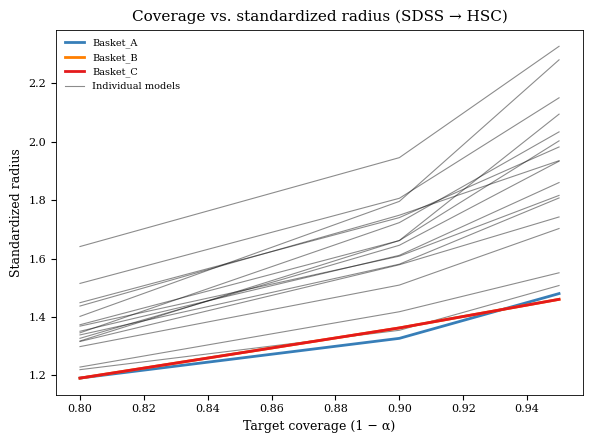

In [6]:
plot_coverage_radius_curve(
    input_csv=f"{RESULTS_DIR}/sdss_coverage_radius_curve.csv",
    output_path=f"{PLOTS_DIR}/sdss_coverage_radius_curve.png",
    title="Coverage vs. standardized radius (SDSS \u2192 HSC)",
)
plt.show()

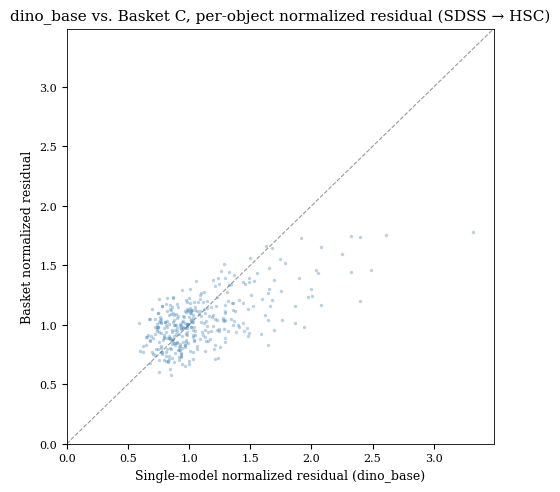

In [8]:
# One scatter per single model, or omit single_model to pool all of them
plot_residual_scatter(
    input_csv=f"{RESULTS_DIR}/sdss_residual_scatter_pairs.csv",
    output_path=f"{PLOTS_DIR}/sdss_residual_scatter_dino_base_vs_basket_c.png",
    single_model="dino_base",
    title="dino_base vs. Basket C, per-object normalized residual (SDSS \u2192 HSC)",
)
plt.show()

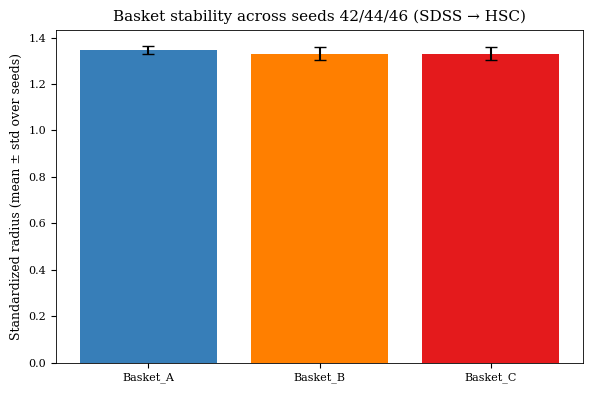

In [10]:
plot_seed_stability(
    input_csv=f"{RESULTS_DIR}/sdss_seed_stability_summary.csv",
    output_path=f"{PLOTS_DIR}/sdss_seed_stability.png",
    title="Basket stability across seeds 42/44/46 (SDSS \u2192 HSC)",
)
plt.show()